# Lesson 3: Model Training and Solution Build

**Complete notebook.** Every cell runs as it is. Run the cells in order, top to
bottom, and read the explanation between them: what matters is what the
output shows and why.

## What this notebook builds

A YOLO26 model fine tuned on two direction classes, `person_left` and
`person_right`, trained on the dataset your team photographed and annotated in
Roboflow, then wrapped in code that reports a count per direction for any new
image.

## The order of work

1. Setup
2. The dataset, downloaded from Roboflow, with the split Roboflow made
3. What a pretrained model cannot tell you
4. Training configuration
5. Training
6. Reading the result
7. Where the model got it wrong
8. Counting, which is what turns a model into the People Counting Assistant

There is no tracking anywhere in this notebook. Direction is a class read from a
single frame. Tracking is Lesson 5.

## Timing

Lab time is roughly 60 minutes and the training run is the long step. Launch it,
then use the wait to read the curves section and start writing the sheet.

---

## 1. Setup

Two installs and a GPU check. Ultralytics is pinned so that all five teams train
with identical behaviour and a result from one team is comparable with another.

In [1]:
# Pinned, so every team trains on the same code.
ULTRALYTICS_VERSION = "8.4.120"

try:
    import google.colab  # noqa: F401
    RUNNING_ON_COLAB = True
except ImportError:
    RUNNING_ON_COLAB = False

if RUNNING_ON_COLAB:
    import subprocess
    # roboflow is left unpinned on purpose. It talks to a hosted service, so the
    # version that matches the service is whichever one is current.
    subprocess.run(
        ["pip", "install", "-q", "ultralytics==" + ULTRALYTICS_VERSION, "roboflow"],
        check=True,
    )

print("Running on Colab:", RUNNING_ON_COLAB)

Running on Colab: True


In [2]:
import json
import os
import random

import torch
from ultralytics import YOLO

print("torch    :", torch.__version__)
print("GPU      :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

if not torch.cuda.is_available():
    print("")
    print("No GPU. In Colab: Runtime, Change runtime type, T4 GPU.")
    print("Training on CPU works but takes far longer than the lab allows.")

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
torch    : 2.14.1+cu130
GPU      : Tesla T4


### Where the work is kept

Everything lands in one folder on Drive, so that closing the runtime does not
lose the trained weights. Lesson 4 reads `best.pt` from the same place.

In [3]:
if RUNNING_ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/C389"
else:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

WORK_DIR = os.path.join(PROJECT_ROOT, "runs", "L3")
os.makedirs(WORK_DIR, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("WORK_DIR    :", WORK_DIR)

Mounted at /content/drive
PROJECT_ROOT: /content/drive/MyDrive/C389
WORK_DIR    : /content/drive/MyDrive/C389/runs/L3


---

## 2. The dataset, from Roboflow

The images were taken on a phone, uploaded as they were, with the phone's own
filenames, and annotated in your team's Roboflow project. Roboflow divides them
into train, valid and test when the version is generated, and this notebook
uses that split as it is.
Roboflow writes the download code for you:

1. In Roboflow, open **Versions** and click your team's version
2. Click **Download Dataset**, choose the **YOLOv8** format, choose **Show download
   code**, and click Continue
3. Copy the code it shows and paste it between the triple quotes in the cell below
4. **Delete the API key from the pasted code**, so that the line reads
   `api_key=""`. The cell asks for the key when it runs

YOLOv8 is the name of the label file layout, one text file per image holding
normalised boxes, and has nothing to do with the model version. Roboflow may offer
YOLO26 first: it writes the same files, and either one works.

The key is a **private** key: anyone holding it can read and change your team's
project. It is never saved inside the notebook, because the notebook is pushed to
your team's repository. If the key is still in the pasted code, the cell stops and
says so.

To avoid typing the key every time, save it once in Colab's **Secrets** panel, the
key icon on the left, under the name `ROBOFLOW_API_KEY`, and allow this notebook to
read it. The cell uses the secret when it finds one and asks otherwise.

Leave the triple quotes empty to fall back to the small sample set in this repo.
The sample images are drawn rather than photographed, so they prove the pipeline
runs and nothing else.


In [4]:
import re
from getpass import getpass

# Paste the download code from Roboflow between the triple quotes, then delete the
# key so the line reads api_key="". Leave it empty to use the sample set.
ROBOFLOW_CODE = """
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="")
project = rf.workspace("c389005-team-4").project("people-counting-assistant-iktz3")
version = project.version(5)
dataset = version.download("yolo26")

"""

SAMPLE_DIR = os.path.join(PROJECT_ROOT, "data", "sample", "walkway")
YOLO_FORMATS = ("yolov8", "yolo26", "yolov11", "yolov12", "yolov9", "yolov5")


def read_roboflow_code(code):
    """Read the workspace, project, version and format out of Roboflow's code.

    Returns None when nothing was pasted. Raises ValueError when the code still
    holds the private key, or lacks a value the download needs.
    """
    if not code.strip():
        return None
    key = re.search(r"api_key\s*=\s*[\"']([^\"']*)[\"']", code)
    if key and key.group(1).strip():
        raise ValueError(
            "The pasted code still holds your private API key. Delete it so the "
            "line reads api_key=\"\", then run the cell again. The key is asked "
            "for when the cell runs, so it is never saved in the notebook.")
    found = {}
    for name, pattern in (("workspace", r"\.workspace\(\s*[\"']([^\"']+)[\"']"),
                          ("project", r"\.project\(\s*[\"']([^\"']+)[\"']"),
                          ("version", r"\.version\(\s*(\d+)\s*\)"),
                          ("format", r"\.download\(\s*[\"']([^\"']+)[\"']")):
        match = re.search(pattern, code)
        if not match:
            raise ValueError(
                "No %s in the pasted code. Copy the whole block Roboflow shows "
                "under Show download code." % name)
        found[name] = match.group(1)
    found["version"] = int(found["version"])
    # YOLOv8, YOLO26 and the other YOLO text formats write the same files: one
    # label file per image and a data.yaml. Anything else is a different layout.
    if found["format"] not in YOLO_FORMATS:
        raise ValueError(
            "The code downloads the %r format. Choose YOLOv8 in the Download "
            "Dataset window and copy the code again." % found["format"])
    return found


def roboflow_key():
    """The private key from Colab Secrets, or else from a hidden prompt."""
    if RUNNING_ON_COLAB:
        try:
            from google.colab import userdata
            return userdata.get("ROBOFLOW_API_KEY").strip()
        except Exception:
            pass  # no secret saved, or this notebook is not allowed to read it
    return getpass("Roboflow private API key: ").strip()


ROBOFLOW = read_roboflow_code(ROBOFLOW_CODE)

if ROBOFLOW:
    from roboflow import Roboflow

    print("workspace %(workspace)s, project %(project)s, version %(version)d" % ROBOFLOW)
    project = Roboflow(api_key=roboflow_key()).workspace(
        ROBOFLOW["workspace"]).project(ROBOFLOW["project"])
    export = project.version(ROBOFLOW["version"]).download(
        ROBOFLOW["format"], location=os.path.join(WORK_DIR, "dataset"), overwrite=True
    )
    DATASET_DIR = export.location
    USING_SAMPLE_DATA = False
else:
    if not os.path.isdir(SAMPLE_DIR):
        raise FileNotFoundError(
            "Nothing was pasted and there is no sample set at %s.\n"
            "Paste the Roboflow download code, or run scripts/make_sample_data.py."
            % SAMPLE_DIR
        )
    DATASET_DIR = SAMPLE_DIR
    USING_SAMPLE_DATA = True

DATA_YAML = os.path.join(DATASET_DIR, "data.yaml")
print("dataset:", DATASET_DIR)

if USING_SAMPLE_DATA:
    print("")
    print("WARNING: using the drawn sample set. It checks that the pipeline runs.")
    print("Every number below is meaningless about the real problem.")


workspace c389005-team-4, project people-counting-assistant-iktz3, version 5
Roboflow private API key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/drive/MyDrive/C389/runs/L3/dataset in yolo26:: 100%|██████████| 1020/1020 [00:08<00:00, 124.59it/s]

dataset: /content/drive/MyDrive/C389/runs/L3/dataset


### The class list

Read from `data.yaml` rather than typed here. A twist that appends a third class
then needs no edit in this notebook.

The order matters and is not cosmetic. Class IDs are positional, so `person_left`
must be 0 and `person_right` must be 1 in every team's export. If the check below
fails, the fix is in Roboflow, not here.

In [5]:
def read_class_names(yaml_path):
    """Read the ordered class list out of a Roboflow data.yaml.

    Parsed by hand rather than with pyyaml, because the one line that matters is
    a plain list and a dependency for it is not worth the install.
    """
    with open(yaml_path, encoding="utf-8") as handle:
        for line in handle:
            if line.startswith("names:"):
                body = line.split(":", 1)[1].strip().strip("[]")
                return [name.strip().strip("'\"") for name in body.split(",")]
    raise ValueError("No names: line in %s" % yaml_path)


CLASS_NAMES = read_class_names(DATA_YAML)
print("classes:", CLASS_NAMES)

EXPECTED_FIRST_TWO = ["person_left", "person_right"]
if CLASS_NAMES[:2] != EXPECTED_FIRST_TWO:
    raise ValueError(
        "The first two classes are %s and must be %s, in that order.\n"
        "Lessons 4 and 5 read the classes by position, so a different order "
        "counts the wrong direction. Fix the class names in Roboflow and export again."
        % (CLASS_NAMES[:2], EXPECTED_FIRST_TWO)
    )

classes: ['person_left', 'person_right', 'wheeled_left', 'wheeled_right']


### Making the dataset path unambiguous

A Roboflow export writes its split paths as `../train/images`. Those are
resolved against the folder the file sits in, so the `..` climbs one level too
high and training stops with a dataset-not-found error naming a path nobody
typed.

The cell below rewrites the file with an absolute `path:` and plain split names.
Nothing about the data changes. It is here because this is the single most common
way a first Colab run fails, and the error message does not say what to do.

In [6]:
def normalise_data_yaml(dataset_dir):
    """Rewrite data.yaml with an absolute path, keeping the class list.

    Returns the path to the file that was written.
    """
    yaml_path = os.path.join(dataset_dir, "data.yaml")
    names_line = None
    with open(yaml_path, encoding="utf-8") as handle:
        for line in handle:
            if line.startswith("names:"):
                names_line = line.rstrip()

    if names_line is None:
        raise ValueError("No names: line in %s" % yaml_path)

    splits = []
    for key, folder in (("train", "train"), ("val", "valid"), ("test", "test")):
        if os.path.isdir(os.path.join(dataset_dir, folder, "images")):
            splits.append("%s: %s/images" % (key, folder))

    if not any(line.startswith("train:") for line in splits):
        raise FileNotFoundError(
            "No train/images folder under %s. The export did not unpack the way "
            "this notebook expects." % dataset_dir)

    class_count = len(read_class_names(yaml_path))
    with open(yaml_path, "w", encoding="utf-8") as handle:
        print("# Paths rewritten by this notebook so that they resolve from",
              "anywhere.", file=handle)
        print("path:", dataset_dir.replace(os.sep, "/"), file=handle)
        for line in splits:
            print(line, file=handle)
        print("", file=handle)
        print("nc:", class_count, file=handle)
        print(names_line, file=handle)
    return yaml_path


normalise_data_yaml(DATASET_DIR)
print(open(DATA_YAML, encoding="utf-8").read())

# Paths rewritten by this notebook so that they resolve from anywhere.
path: /content/drive/MyDrive/C389/runs/L3/dataset
train: train/images
val: valid/images
test: test/images

nc: 4
names: ['person_left', 'person_right', 'wheeled_left', 'wheeled_right']



### The split Roboflow made

Roboflow put each image in one of three folders when the version was generated:
`train` is what the model learns from, `valid` is what it is checked against while
it trains, and `test` is kept back for the final score in Section 6.

The cell below counts what landed where. A version generated with no test images
still works: the notebook then reports its final score on `valid` and says so.

In [7]:
SPLIT_FOLDERS = ["train", "valid", "test"]


def count_images(dataset_dir, split):
    """How many images one split folder holds, 0 when the folder is missing."""
    image_dir = os.path.join(dataset_dir, split, "images")
    if not os.path.isdir(image_dir):
        return 0
    return sum(1 for name in os.listdir(image_dir)
               if name.lower().endswith((".jpg", ".jpeg", ".png")))


SPLIT_COUNTS = {split: count_images(DATASET_DIR, split) for split in SPLIT_FOLDERS}
for split in SPLIT_FOLDERS:
    print("%-6s %4d images" % (split, SPLIT_COUNTS[split]))

if not SPLIT_COUNTS["train"]:
    raise ValueError("The version has no training images. Generate it again in "
                     "Roboflow with images in Train.")

# The split every result below is judged on. Ultralytics calls the valid folder "val".
EVAL_FOLDER = "test" if SPLIT_COUNTS["test"] else "valid"
EVAL_SPLIT = "test" if EVAL_FOLDER == "test" else "val"
if EVAL_FOLDER == "valid":
    print("")
    print("No test images, so the final score is read on valid instead.")

train   355 images
valid   102 images
test     51 images


---

## 3. What a pretrained model cannot tell you

Before training anything, run the stock model. It was trained on COCO, which has
a `person` class and nothing direction aware.

Two images are run: a photograph that ships with Ultralytics, and one image from
this dataset. Watch the class of every detection on the photograph. The boxes
will be in the right places and every one of them will say `person`.

In [8]:
def image_paths(dataset_dir, split, limit=None):
    """List the images in one split, in filename order."""
    image_dir = os.path.join(dataset_dir, split, "images")
    names = sorted(name for name in os.listdir(image_dir)
                   if name.lower().endswith((".jpg", ".jpeg", ".png")))
    if limit:
        names = names[:limit]
    return [os.path.join(image_dir, name) for name in names]


def to_detections(result, class_names):
    """Turn one Ultralytics result into plain dictionaries.

    The same shape is used in the service in Lesson 4, so the counting code
    written below is the code that ships.
    """
    detections = []
    boxes = result.boxes
    if boxes is None:
        return detections
    for index in range(len(boxes)):
        class_id = int(boxes.cls[index].item())
        name = class_names[class_id] if class_id < len(class_names) else str(class_id)
        detections.append({
            "class_name": name,
            "confidence": round(float(boxes.conf[index].item()), 3),
            "box": [round(float(value), 1) for value in boxes.xyxy[index].tolist()],
        })
    return detections


from ultralytics.utils import ASSETS

BASELINE_MODEL = "yolo26n.pt"
pretrained = YOLO(BASELINE_MODEL)
pretrained_names = [pretrained.names[key] for key in sorted(pretrained.names)]

# A real photograph first, then one image from this dataset. The photograph is
# what carries the point, and it is here because a model trained on photographs
# has never seen a drawing and reports nothing on the sample set.
baseline_paths = [os.path.join(str(ASSETS), "bus.jpg")]
baseline_paths += image_paths(DATASET_DIR, EVAL_FOLDER, limit=1)

for path in baseline_paths:
    result = pretrained.predict(path, conf=0.35, verbose=False)[0]
    detections = to_detections(result, pretrained_names)
    print(os.path.basename(path))
    for detection in detections:
        print("   %-12s %.2f" % (detection["class_name"], detection["confidence"]))
    if not detections:
        print("   nothing detected")

bus.jpg
   bus          0.92
   person       0.91
   person       0.91
   person       0.87
   person       0.53
20261104_140043_031_jpg.rf.bc358be49d51e41c5473f97248ed73b3.jpg
   person       0.87
   person       0.84
   person       0.73
   bicycle      0.69
   person       0.66
   bicycle      0.63


On the photograph, every line says `person`. Nothing in that output distinguishes
somebody walking left from somebody walking right, and no confidence threshold,
no image size and no larger model variant will change it. The information is not
missing because the model is weak. It is missing because nobody ever trained it
to report direction.

That is why the next six sections exist, and it is the answer to give anyone who
asks why a pretrained model could not simply be used.

**On the drawn sample images the stock model reports nothing at all.** That is
not the same finding and it is worth being clear about. A model trained on
photographs has never seen a line drawing of a person, so it does not recognise
one. On photographs taken by this class it will find people reliably, and it will
still only ever say `person`.

---

## 4. Training configuration

Four values to choose and one that is not a choice.

Each of the four costs something. A larger variant is more accurate and slower to
train and to serve. More epochs fit the training set better and eventually fit
its noise. A larger image size helps with people far from the camera, which is
where direction is hardest to read, and uses more memory. Batch size is the first
thing to reduce when the run dies out of memory.

### Epochs is the wrong thing to count

What the model actually gets is **optimiser steps**, which is the number of
training images divided by the batch size, multiplied by the epochs.

Twenty four images at batch 16 is one and a half steps per epoch, so thirty
epochs is about forty five steps. Forty five steps is enough for the model to
learn roughly where people are, so mAP comes out looking reasonable, and nowhere
near enough for it to become confident about anything. Every prediction then
arrives below any sensible threshold and every count comes out zero.

A small dataset needs more epochs, not fewer. The cell after training prints the
number of steps this configuration will produce, so the figure is visible rather
than inferred.

Be ready to give the reason for each value. The value matters less than being
able to say why.

In [9]:
MODEL_VARIANT = "yolo26n.pt"
EPOCHS = 100
IMAGE_SIZE = 640
BATCH_SIZE = 16

In [10]:
# fliplr is pre-written and must stay at 0.0.
#
# Horizontal flip augmentation mirrors the image and keeps the original label. A
# flipped person_left is a person moving right, still labelled person_left, so
# the model is taught the opposite of the truth on half the data. Nothing in the
# output reveals it: the curves look normal and the score looks reasonable. This
# is the one setting in this notebook that is not a choice.
FLIP_LEFT_RIGHT = 0.0

RUN_NAME = "people_counting_baseline"

missing = [name for name, value in (
    ("MODEL_VARIANT", MODEL_VARIANT), ("EPOCHS", EPOCHS),
    ("IMAGE_SIZE", IMAGE_SIZE), ("BATCH_SIZE", BATCH_SIZE)) if value is None]
if missing:
    raise ValueError("Set these before launching: %s" % ", ".join(missing))

training_images = len(image_paths(DATASET_DIR, "train"))
steps_per_epoch = max(1, training_images // BATCH_SIZE)
total_steps = steps_per_epoch * EPOCHS

print("model variant :", MODEL_VARIANT)
print("epochs        :", EPOCHS)
print("image size    :", IMAGE_SIZE)
print("batch size    :", BATCH_SIZE)
print("fliplr        :", FLIP_LEFT_RIGHT, "(must be 0.0)")
print("")
print("training images  : %d" % training_images)
print("optimiser steps  : %d per epoch, %d in total" % (steps_per_epoch, total_steps))

if total_steps < 300:
    print("")
    print("That is a small number of steps. Expect a model that finds roughly the")
    print("right places and is not confident about any of them, which shows up as")
    print("counts of zero in Section 8. Raise the epochs rather than the threshold.")

model variant : yolo26n.pt
epochs        : 100
image size    : 640
batch size    : 16
fliplr        : 0.0 (must be 0.0)

training images  : 355
optimiser steps  : 22 per epoch, 2200 in total


---

## 5. Training

One call. While it runs, read the next section so that the curves mean something
when they appear, and start Section 1 of the sheet.

In [11]:
model = YOLO(MODEL_VARIANT)

results = model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    fliplr=FLIP_LEFT_RIGHT,
    project=WORK_DIR,
    name=RUN_NAME,
    exist_ok=True,
    seed=0,
)

RUN_DIR = os.path.join(WORK_DIR, RUN_NAME)
BEST_WEIGHTS = os.path.join(RUN_DIR, "weights", "best.pt")
print("")
print("weights:", BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.211 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.120 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/C389/runs/L3/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=30

---

## 6. Reading the result

Per class, never only the overall mean. The mean hides the failure this project
is most likely to have: one direction learned well and the other not, which comes
from class imbalance or from inconsistent annotation, and not from the model.

In [13]:
trained = YOLO(BEST_WEIGHTS)
metrics = trained.val(data=DATA_YAML, split=EVAL_SPLIT, verbose=False)

PER_CLASS = {}
for index, class_id in enumerate(metrics.ap_class_index):
    PER_CLASS[CLASS_NAMES[int(class_id)]] = {
        "precision": float(metrics.box.p[index]),
        "recall": float(metrics.box.r[index]),
        "ap50": float(metrics.box.ap50[index]),
        "ap50_95": float(metrics.box.ap[index]),
    }

print("%-14s %9s %7s %8s %9s" % ("class", "precision", "recall", "mAP@.5", "mAP@.5:.95"))
for name in CLASS_NAMES:
    if name in PER_CLASS:
        row = PER_CLASS[name]
        print("%-14s %9.3f %7.3f %8.3f %9.3f"
              % (name, row["precision"], row["recall"], row["ap50"], row["ap50_95"]))

scores = [PER_CLASS[name]["ap50"] for name in PER_CLASS]
if len(scores) > 1:
    gap = max(scores) - min(scores)
    print("")
    print("gap between the best and worst class, mAP@.5: %.3f" % gap)
    if gap >= 0.10:
        print("")
        print("That is a wide gap, and it points at the data rather than the model.")
        print("One direction has either fewer annotated instances than the other or")
        print("less consistent ones. Check the class balance before changing any")
        print("training setting, because no setting fixes an imbalance.")
    else:
        print("The two directions were learned about equally well. Nothing to chase.")

Ultralytics 8.4.120 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,616 parameters, 0 gradients, 5.3 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 46.3±8.0 MB/s, size: 45.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/drive/MyDrive/C389/runs/L3/dataset/test/labels.cache... 51 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 51/51 14.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.6it/s 2.5s
                   all         51        130       0.96      0.773      0.884      0.762
Speed: 10.2ms preprocess, 7.7ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /content/runs/detect/val-2
class          precision  recall   mAP@.5 mAP@.5:.95
person_left        0.918   0.641    0.792     0.

results.png


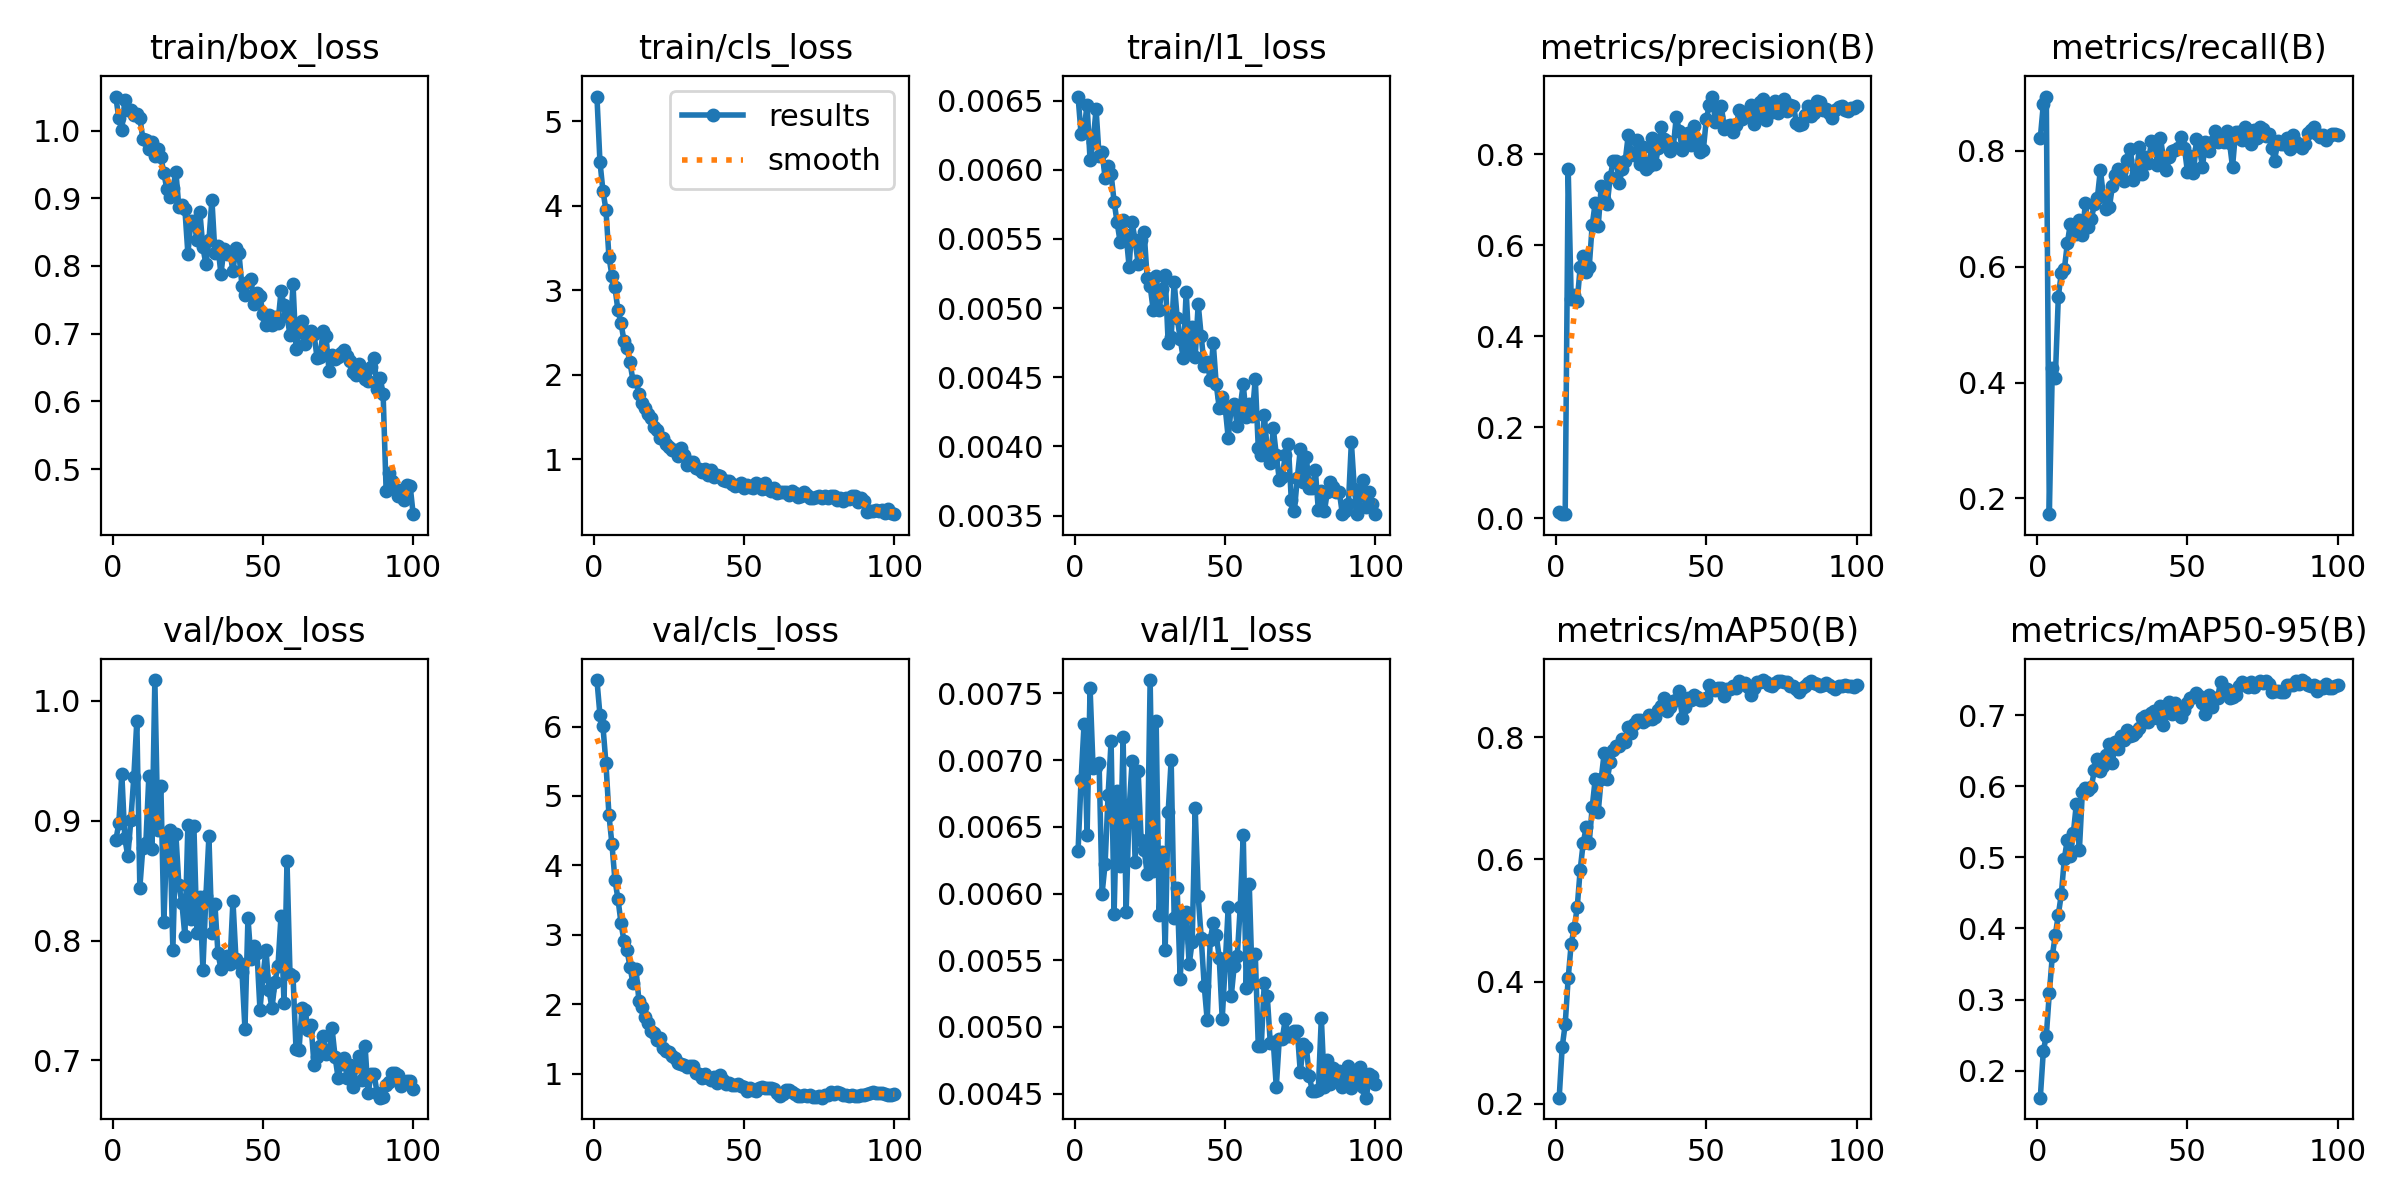

BoxPR_curve.png


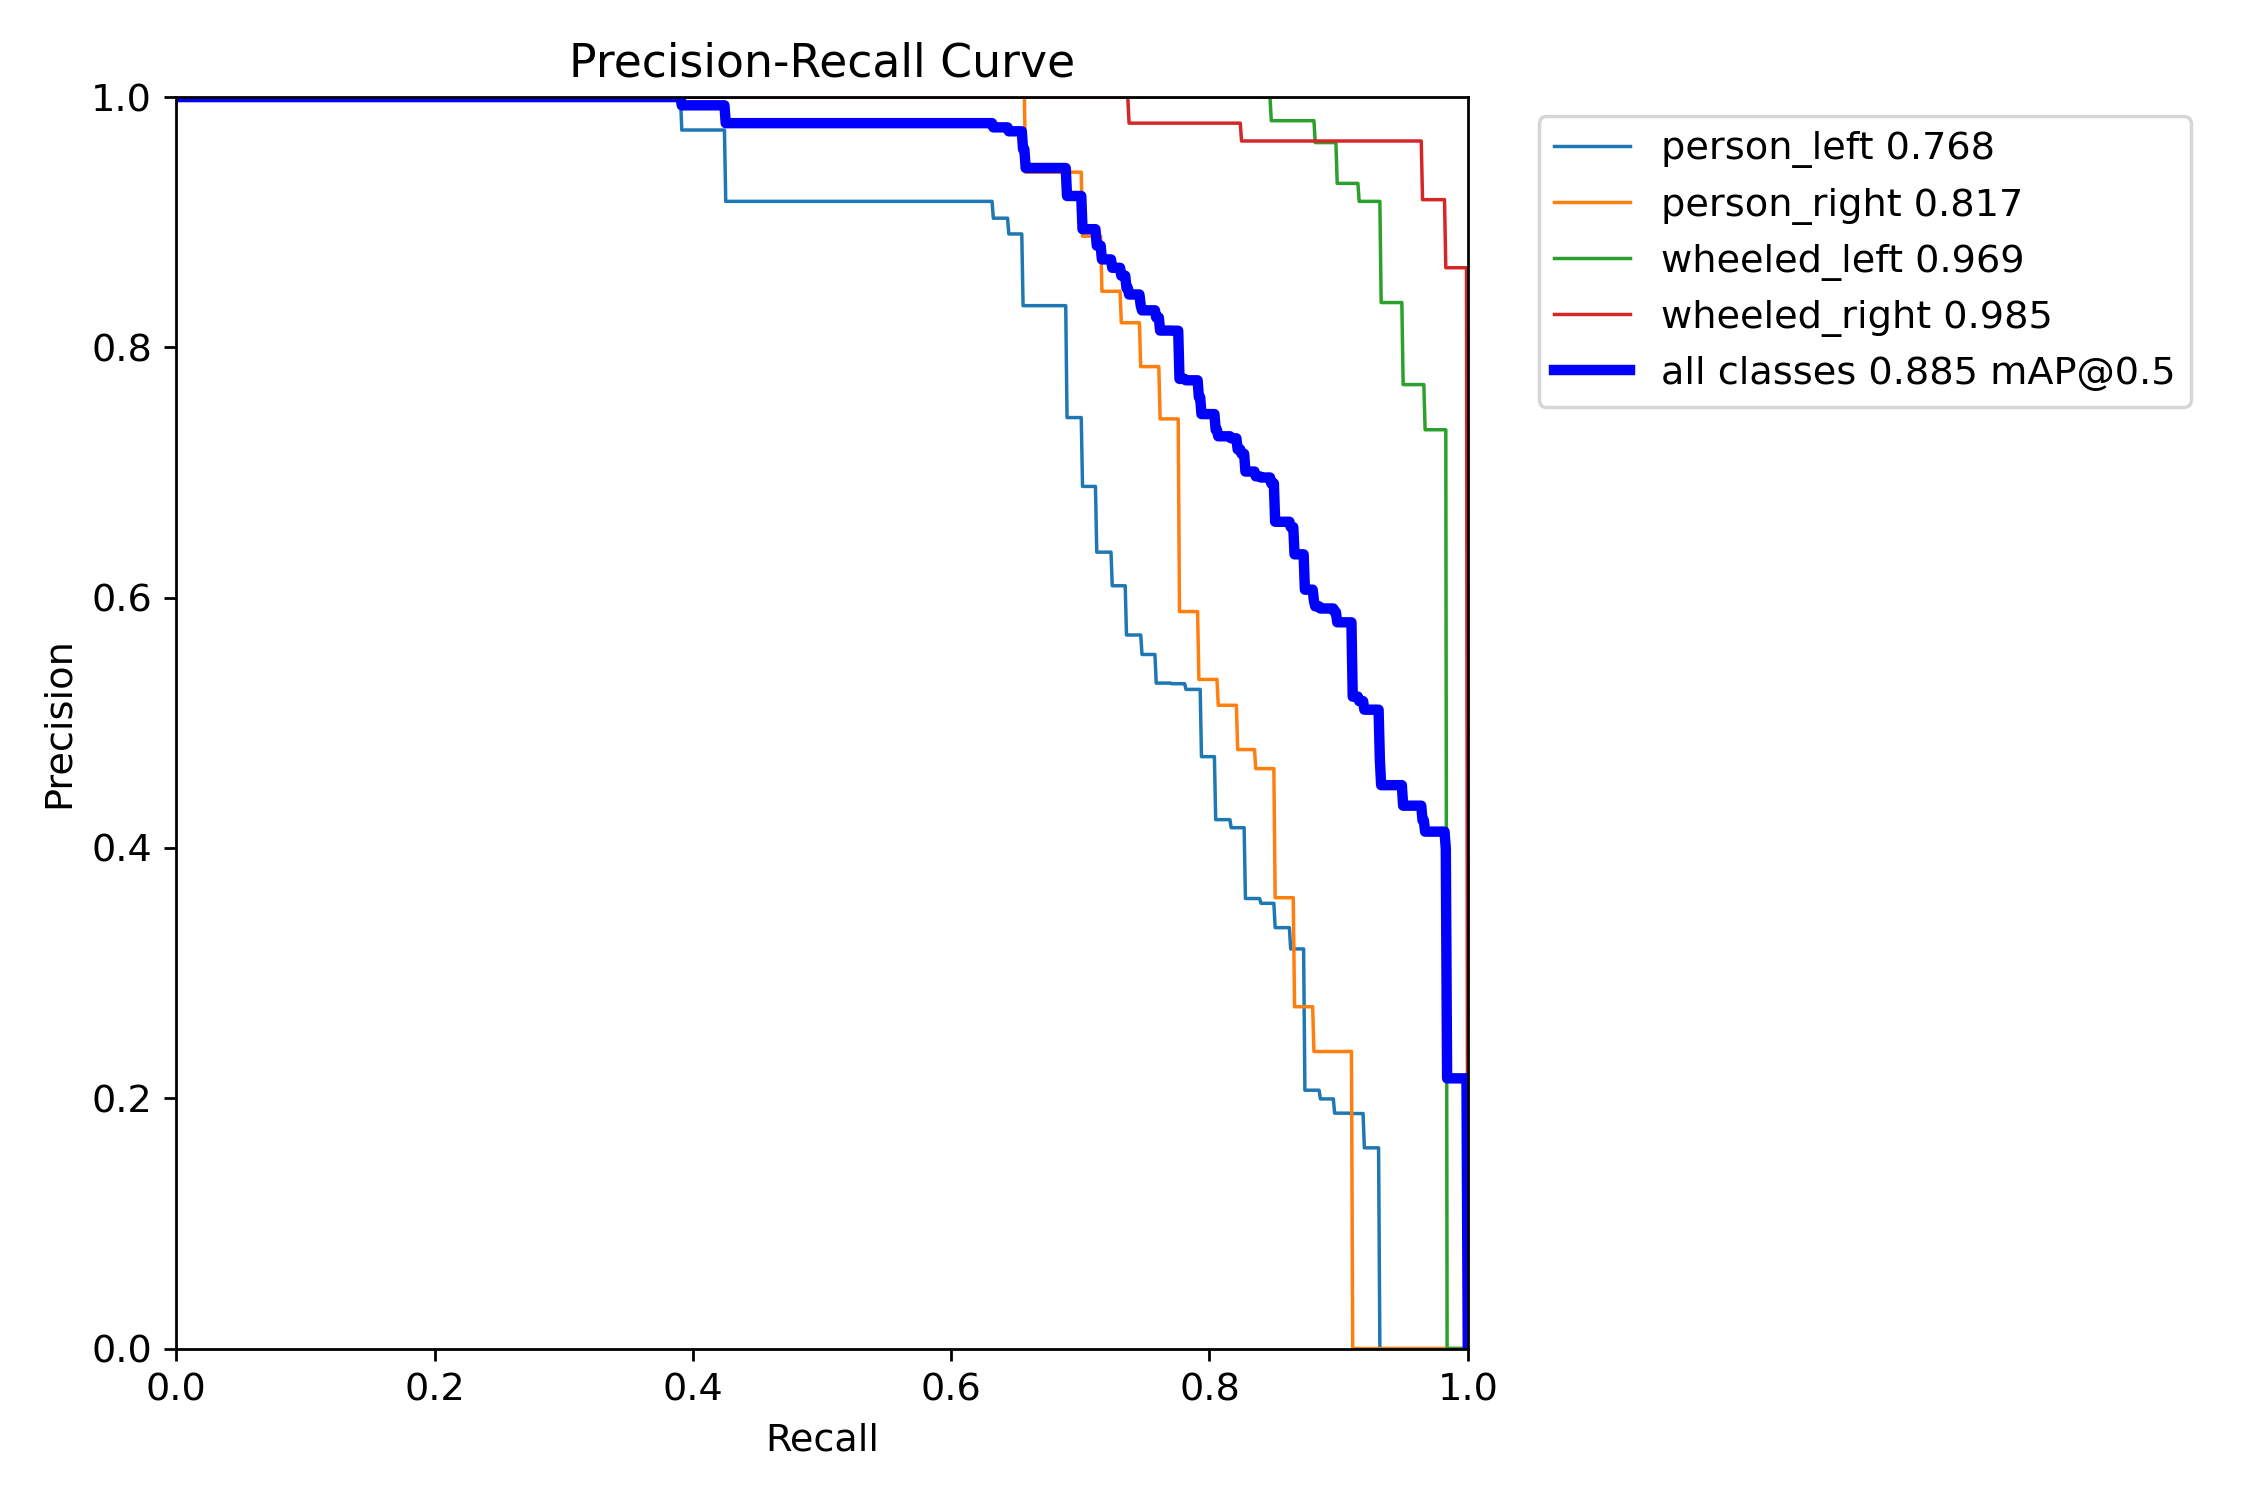

confusion_matrix.png


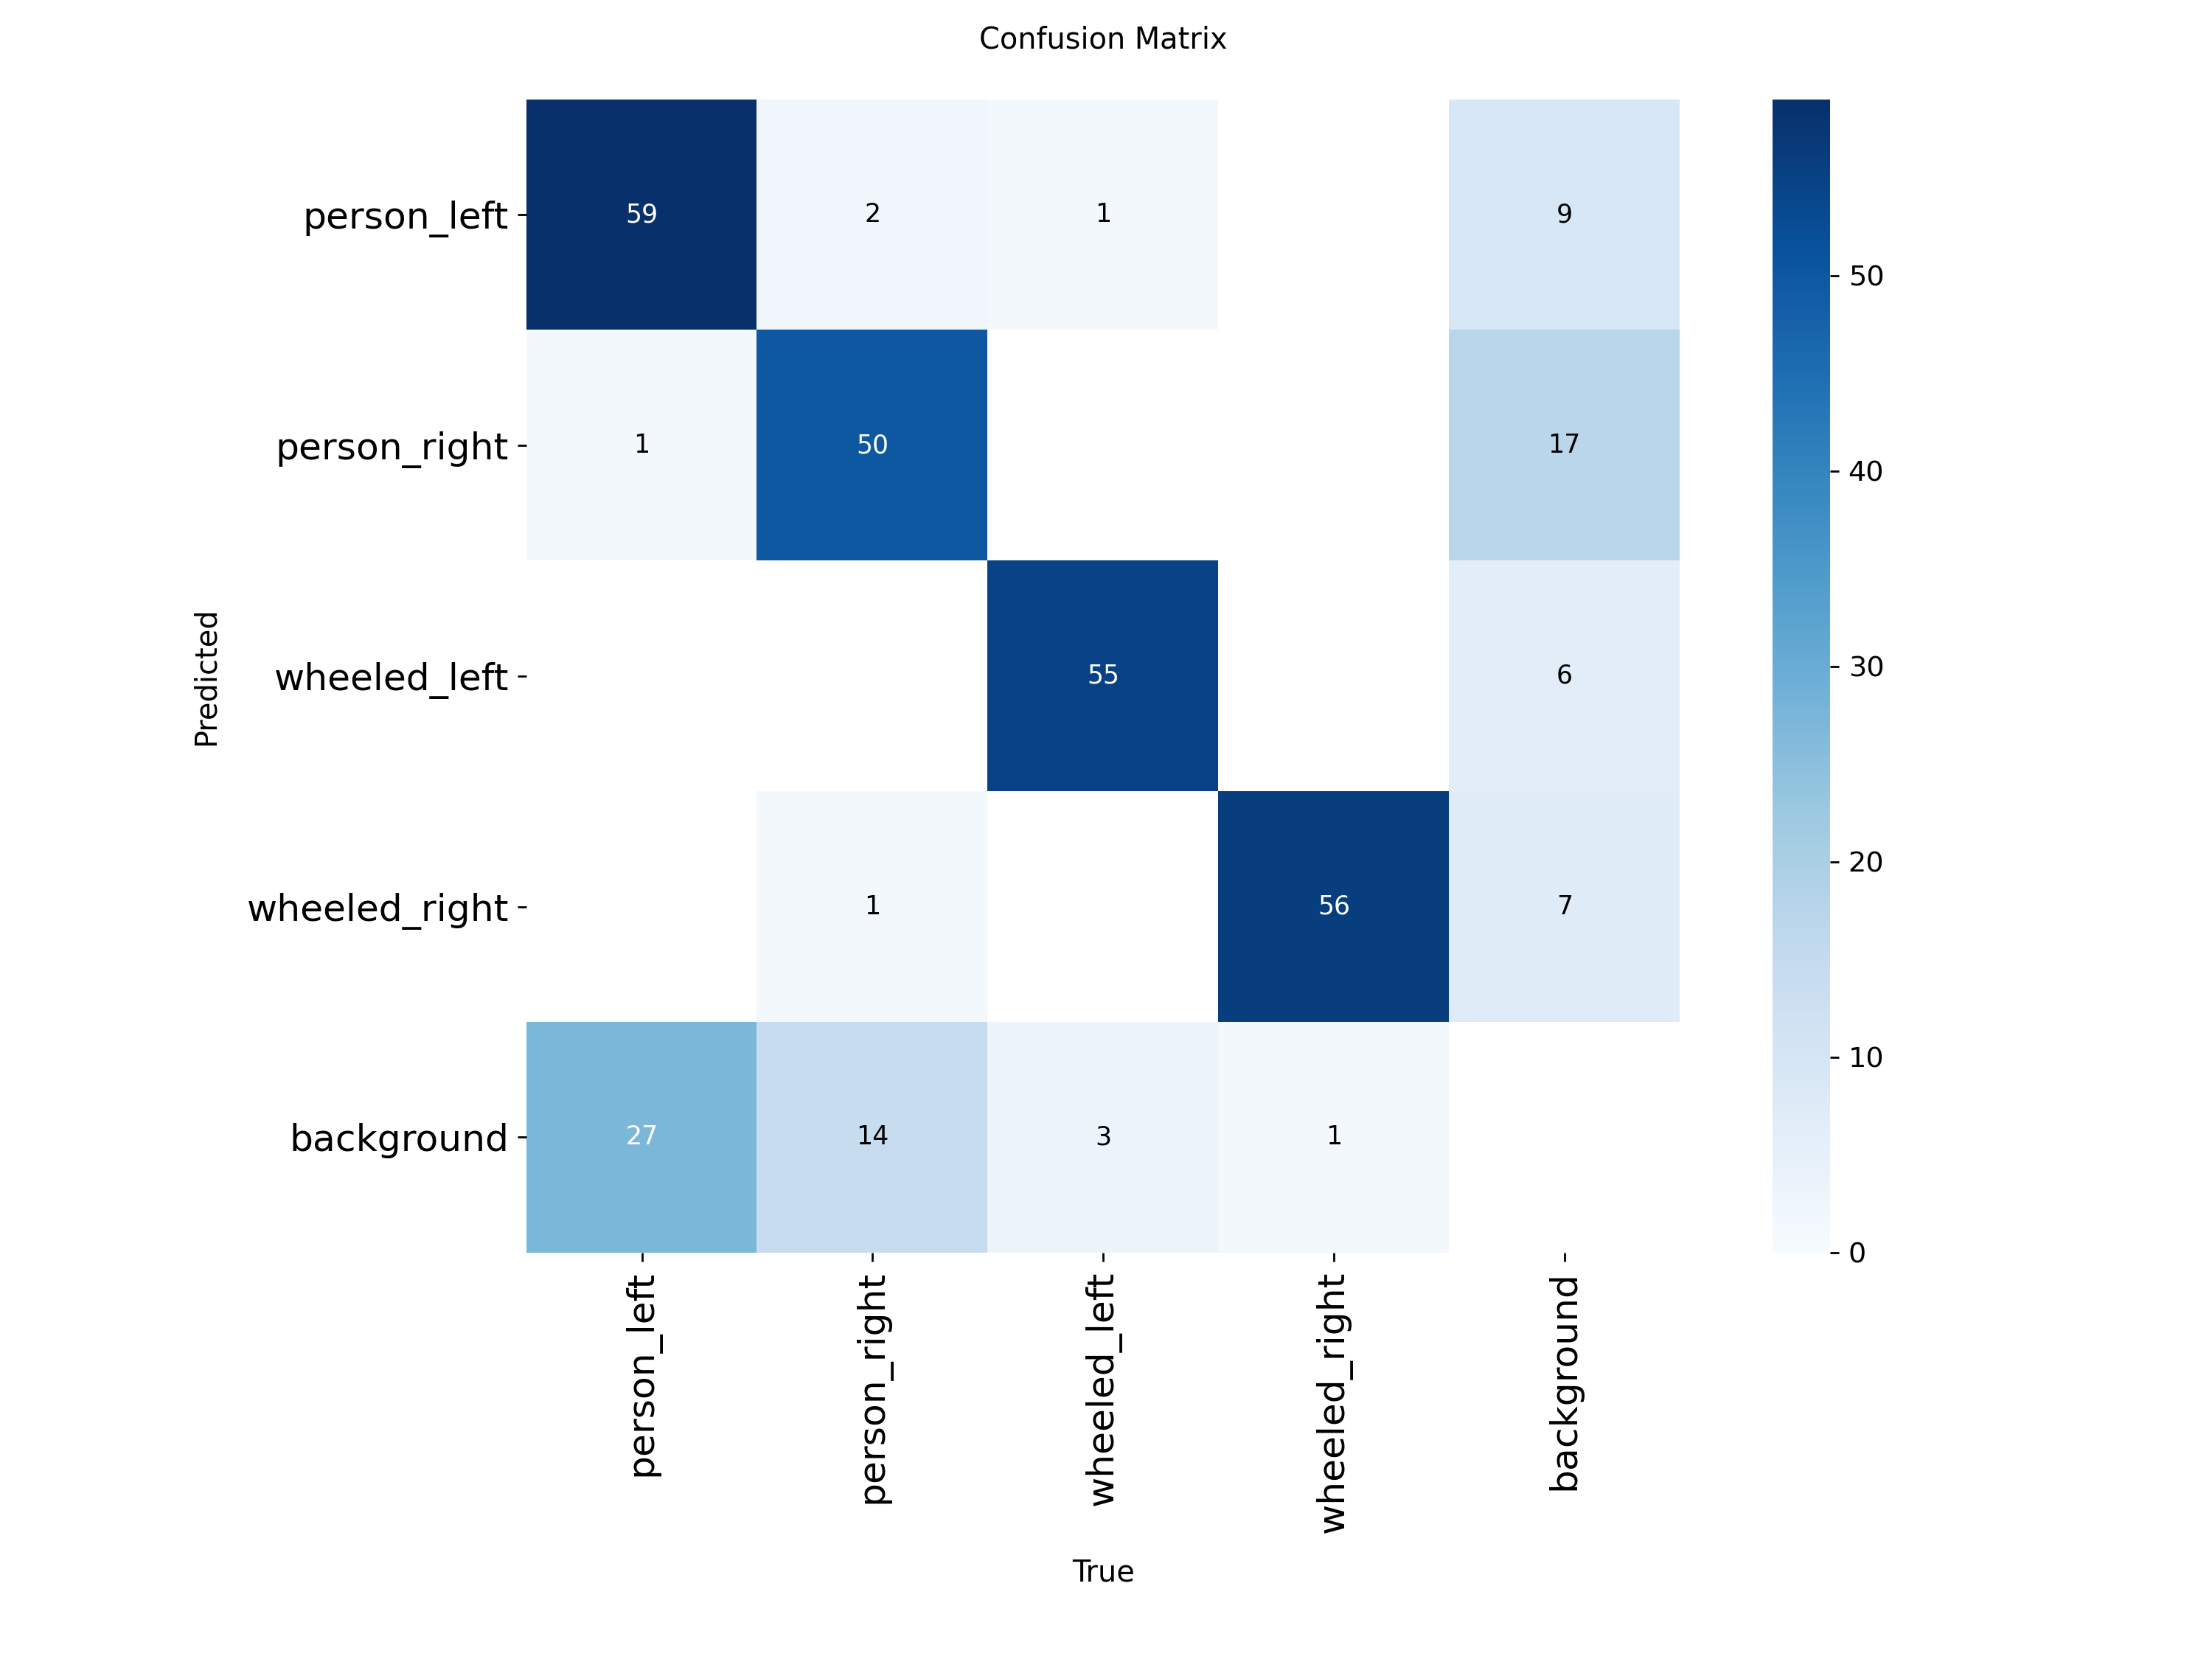

In [14]:
from IPython.display import Image as ShowImage, display
from PIL import Image as PILImage

for name in ("results.png", "BoxPR_curve.png", "confusion_matrix.png"):
    path = os.path.join(RUN_DIR, name)
    if os.path.exists(path):
        print(name)
        display(ShowImage(filename=path, width=760))

Read the curves before the numbers.

- **The loss curves** in `results.png`. Training loss falling while validation
  loss rises is the model fitting this particular set of photographs rather than
  the problem. Both still falling at the last epoch means the run stopped early.
- **The PR curve.** A curve that holds high precision as recall increases is a
  model that is confident and right. One that collapses early is a model guessing.
- **The confusion matrix.** Look at the `person_left` against `person_right` cell
  specifically. Confusion between the two directions is the failure mode of this
  project, and it is different from failing to find a person at all.

What goes on the sheet is what these curves show for **this** run, including the
places they disappoint. A run that went wrong and is read correctly is worth more
than a good number nobody can explain.

In [2]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q ultralytics==8.4.120

import os, glob
from ultralytics import YOLO

DATASET_DIR = "/content/drive/MyDrive/C389/runs/L3/dataset"
EVAL_FOLDER = "test"
BEST_WEIGHTS = "/content/drive/MyDrive/C389/runs/L3/people_counting_baseline/weights/best.pt"
CLASS_NAMES = ['person_left', 'person_right', 'wheeled_left', 'wheeled_right']

trained = YOLO(BEST_WEIGHTS)

def image_paths(dataset_dir, folder, limit=None):
    paths = sorted(glob.glob(os.path.join(dataset_dir, folder, "images", "*.jpg")))
    return paths[:limit] if limit else paths

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
import os
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

CONF = 0.40          # use 0.50 if that is the threshold you report
MAX_IMAGES = 8       # how many test images to show
ONLY_DIFFERENT = True  # True = show only images where the counts differ

COLOURS = {"person_left": "#1f77b4", "person_right": "#ff7f0e",
           "wheeled_left": "#2ca02c", "wheeled_right": "#d62728"}

def gt_boxes(image_path, size):
    """Read YOLO labels (class cx cy w h, normalised) -> pixel boxes."""
    label_path = image_path.replace(os.sep + "images" + os.sep, os.sep + "labels" + os.sep)
    label_path = os.path.splitext(label_path)[0] + ".txt"
    W, H = size
    boxes = []
    if os.path.exists(label_path):
        for line in open(label_path, encoding="utf-8"):
            if line.strip():
                c, cx, cy, w, h = line.split()[:5]
                cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
                boxes.append((CLASS_NAMES[int(c)], cx - w/2, cy - h/2, cx + w/2, cy + h/2, None))
    return boxes

def pred_boxes(image_path):
    r = trained.predict(image_path, conf=CONF, verbose=False)[0]
    out = []
    for b, c, s in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist()):
        out.append((CLASS_NAMES[int(c)], *b, s))
    return out

def draw(image_path, boxes):
    img = Image.open(image_path).convert("RGB")
    d = ImageDraw.Draw(img)
    for name, x1, y1, x2, y2, score in boxes:
        col = COLOURS.get(name, "white")
        d.rectangle([x1, y1, x2, y2], outline=col, width=3)
        label = name if score is None else f"{name} {score:.2f}"
        d.text((x1 + 3, max(y1 - 12, 0)), label, fill=col)
    return img

shown = 0
for path in image_paths(DATASET_DIR, EVAL_FOLDER):
    img = Image.open(path)
    gt = gt_boxes(path, img.size)
    pr = pred_boxes(path)

    gt_names = sorted(b[0] for b in gt)
    pr_names = sorted(b[0] for b in pr)
    if ONLY_DIFFERENT and gt_names == pr_names:
        continue

    fig, ax = plt.subplots(1, 2, figsize=(11, 5.5))
    ax[0].imshow(draw(path, gt));  ax[0].set_title(f"Ground truth ({len(gt)} boxes)")
    ax[1].imshow(draw(path, pr));  ax[1].set_title(f"Predicted ({len(pr)} boxes, conf>={CONF})")
    for a in ax: a.axis("off")
    fig.suptitle(os.path.basename(path)[:40], fontsize=9)
    plt.tight_layout(); plt.show()

    shown += 1
    if shown >= MAX_IMAGES:
        break

if shown == 0:
    print("No differing images found. Set ONLY_DIFFERENT = False to see all.")

Output hidden; open in https://colab.research.google.com to view.

---

## 7. Where it got it wrong

Predictions against the held out test split, side by side with the annotation.
Both an error the model made and a case it got right despite looking hard are
worth writing down.

In [15]:
def truth_for(image_path, class_names):
    """Read the annotated classes for one image from its label file."""
    label_path = image_path.replace(os.sep + "images" + os.sep,
                                    os.sep + "labels" + os.sep)
    label_path = os.path.splitext(label_path)[0] + ".txt"
    found = []
    if os.path.exists(label_path):
        with open(label_path, encoding="utf-8") as handle:
            for line in handle:
                if line.strip():
                    class_id = int(line.split()[0])
                    if class_id < len(class_names):
                        found.append(class_names[class_id])
    return sorted(found)


CONFIDENCE_FOR_REVIEW = 0.40

print("%-34s %-26s %s" % ("image", "annotated", "predicted"))
for path in image_paths(DATASET_DIR, EVAL_FOLDER, limit=8):
    result = trained.predict(path, conf=CONFIDENCE_FOR_REVIEW, verbose=False)[0]
    predicted = sorted(d["class_name"] for d in to_detections(result, CLASS_NAMES))
    truth = truth_for(path, CLASS_NAMES)
    flag = "  <-- differs" if predicted != truth else ""
    print("%-34s %-26s %s%s"
          % (os.path.basename(path)[:34], ", ".join(truth) or "none",
             ", ".join(predicted) or "none", flag))

image                              annotated                  predicted
20261104_140043_031_jpg.rf.bc358be person_left, person_right, wheeled_left, wheeled_right person_left, person_right, wheeled_left, wheeled_right
20261104_140043_051_jpg.rf.552d1c7 person_left, person_right, wheeled_left, wheeled_right person_left, person_right, wheeled_left, wheeled_left, wheeled_right  <-- differs
20261104_140043_056_jpg.rf.fe8ceda person_left, person_left, person_left, person_right, wheeled_left, wheeled_right person_right, wheeled_left, wheeled_right  <-- differs
20261104_140043_064_jpg.rf.facb392 person_left, person_left, person_left, person_right, person_right, person_right, wheeled_left, wheeled_right person_left, person_right, person_right, wheeled_left, wheeled_right  <-- differs
20261104_140043_074_jpg.rf.833801d person_right, wheeled_left person_right, person_right, wheeled_left  <-- differs
20261104_140043_094_jpg.rf.0e4fe1f person_left, person_right, wheeled_left, wheeled_right person_l

20261104_140043_051_jpg.rf.552d1c744b78898438724ef50eb395a9.jpg


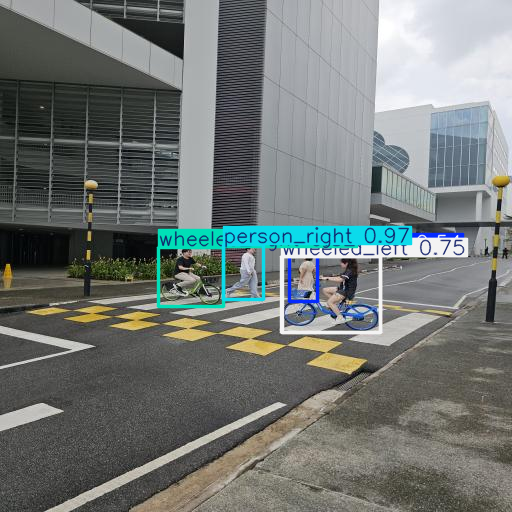

In [16]:
# Look at the ones that differed. Reading the picture is what tells you whether
# the model missed a person entirely or found the person and read the direction
# backwards. Those are two different problems with two different fixes.
for path in image_paths(DATASET_DIR, EVAL_FOLDER, limit=8):
    result = trained.predict(path, conf=CONFIDENCE_FOR_REVIEW, verbose=False)[0]
    predicted = sorted(d["class_name"] for d in to_detections(result, CLASS_NAMES))
    if predicted != truth_for(path, CLASS_NAMES):
        print(os.path.basename(path))
        # result.plot() returns a BGR array. PIL wants RGB, so the channels are
        # reversed before display.
        display(PILImage.fromarray(result.plot()[:, :, ::-1]))
        break
else:
    print("Nothing in the first eight test images differed.")

Take the rows that differ onto the sheet, as they came out, including the ones
where the prediction written down beforehand turned out to be wrong. A prediction
that missed is evidence of the same quality as one that landed.

---

## 8. Counting

The model reports boxes. The People Counting Assistant reports two numbers. The
step between them is short and every decision in it has to be defended.

A count is **per image**. One person photographed ten times is ten detections and
one person. Nothing below sums across images, and nothing should.

In [17]:
# Named once, here, and used everywhere below. The value is a decision, and it is
# one of the things the sheet asks to be justified.
CONFIDENCE_THRESHOLD = 0.5

### Is there anything to threshold

Before choosing a value, find out what range the model is actually producing. A
threshold is a decision about where to cut a distribution, and it means nothing
if the whole distribution sits below it.

In [18]:
best_confidence = 0.0
for path in image_paths(DATASET_DIR, EVAL_FOLDER):
    result = trained.predict(path, conf=0.001, verbose=False)[0]
    for detection in to_detections(result, CLASS_NAMES):
        if detection["confidence"] > best_confidence:
            best_confidence = detection["confidence"]

print("highest confidence anywhere on the %s split : %.3f" % (EVAL_FOLDER, best_confidence))
print("the threshold chosen above : %.2f" % CONFIDENCE_THRESHOLD)

if best_confidence < CONFIDENCE_THRESHOLD:
    print("")
    print("Nothing reaches the threshold, so every count below will be zero.")
    print("The threshold is not the problem and lowering it is not the fix. The")
    print("model is under trained: it has learned roughly where people are and")
    print("has not learned to be sure. Go back to Section 4, raise the epochs,")
    print("and run again. The optimiser step count printed there is the number")
    print("to change.")

highest confidence anywhere on the test split : 0.999
the threshold chosen above : 0.50


In [19]:
def count_people(model, image_path, class_names, threshold):
    """Count the people in one image, grouped by direction class.

    Args:
        model: the trained YOLO model
        image_path: path to a single image
        class_names: the ordered class list read from data.yaml
        threshold: detections below this confidence are dropped

    Returns:
        (counts, kept), where counts maps every class name to a whole number and
        kept is the list of detections that survived the threshold

    Requirement:
        Every class appears in counts, including the ones at zero. A caller
        reading the result should never have to guess whether a missing name
        means none were found or means the class does not exist.

        An image with nobody in it is a valid result of zero, not an error.
    """
    result = model.predict(image_path, conf=0.01, verbose=False)[0]
    detections = to_detections(result, class_names)

    kept = []
    for detection in detections:
        if detection["confidence"] >= threshold:
            kept.append(detection)

    counts = {}
    for name in class_names:
        counts[name] = 0
    for detection in kept:
        counts[detection["class_name"]] = counts[detection["class_name"]] + 1

    return counts, kept

In [20]:
for path in image_paths(DATASET_DIR, EVAL_FOLDER, limit=4):
    counts, kept = count_people(trained, path, CLASS_NAMES, CONFIDENCE_THRESHOLD)
    print("%-34s %s" % (os.path.basename(path)[:34],
                        "  ".join("%s=%d" % (n, counts[n]) for n in CLASS_NAMES)))

20261104_140043_031_jpg.rf.bc358be person_left=1  person_right=1  wheeled_left=1  wheeled_right=1
20261104_140043_051_jpg.rf.552d1c7 person_left=1  person_right=1  wheeled_left=2  wheeled_right=1
20261104_140043_056_jpg.rf.fe8ceda person_left=0  person_right=1  wheeled_left=1  wheeled_right=1
20261104_140043_064_jpg.rf.facb392 person_left=1  person_right=1  wheeled_left=1  wheeled_right=1


### What the threshold is doing

One image, counted at five thresholds. The number the service reports is a
consequence of a value somebody chose, and this is the cell that makes that
visible.

A low threshold finds more people and invents some. A high threshold reports only
what it is sure of and misses the ones half out of frame. There is no correct
value, only a value with a reason attached to it.

The detections themselves are printed first. The table below them is a
consequence of those numbers, and reading the table without them makes a
threshold look like a dial with arbitrary effects.

In [21]:
sample_path = image_paths(DATASET_DIR, EVAL_FOLDER, limit=1)[0]
print(os.path.basename(sample_path))
print("")

everything = to_detections(
    trained.predict(sample_path, conf=0.001, verbose=False)[0], CLASS_NAMES)
everything.sort(key=lambda detection: detection["confidence"], reverse=True)

print("every detection in this image, most confident first")
for detection in everything[:12]:
    print("   %-14s %.3f" % (detection["class_name"], detection["confidence"]))
if len(everything) > 12:
    print("   ... and %d more below these" % (len(everything) - 12))
print("")
print("%-11s %s" % ("threshold", "counts"))
for threshold in (0.15, 0.25, 0.40, 0.60, 0.80):
    counts, kept = count_people(trained, sample_path, CLASS_NAMES, threshold)
    print("%-11.2f %s  (%d detections kept)"
          % (threshold, "  ".join("%s=%d" % (n, counts[n]) for n in CLASS_NAMES),
             len(kept)))

20261104_140043_031_jpg.rf.bc358be49d51e41c5473f97248ed73b3.jpg

every detection in this image, most confident first
   person_right   0.987
   person_left    0.977
   wheeled_left   0.974
   wheeled_right  0.966
   person_left    0.134
   person_left    0.081
   person_right   0.040
   person_right   0.019
   person_left    0.004
   person_left    0.002
   person_right   0.002
   person_left    0.002
   ... and 6 more below these

threshold   counts
0.15        person_left=1  person_right=1  wheeled_left=1  wheeled_right=1  (4 detections kept)
0.25        person_left=1  person_right=1  wheeled_left=1  wheeled_right=1  (4 detections kept)
0.40        person_left=1  person_right=1  wheeled_left=1  wheeled_right=1  (4 detections kept)
0.60        person_left=1  person_right=1  wheeled_left=1  wheeled_right=1  (4 detections kept)
0.80        person_left=1  person_right=1  wheeled_left=1  wheeled_right=1  (4 detections kept)


Compare the table against the list above it. The count only changes where a
threshold crosses one of those confidence values, so a run whose detections are
all bunched together produces a table that is flat and then falls off a cliff,
while a run with confidences spread out produces a table that steps down
gradually. Neither shape is wrong, and the shape is worth a sentence on the
sheet, because it says how much room there was to choose.

Record the chosen threshold together with what it costs. A threshold tuned until
the count matches on one image is tuned to one image.

In [22]:
results = {}
for t in (0.35, 0.40, 0.50, 0.60, 0.70):
    err = {n: 0 for n in CLASS_NAMES}
    for p in image_paths(DATASET_DIR, EVAL_FOLDER):
        counts, _ = count_people(trained, p, CLASS_NAMES, t)
        truth = truth_for(p, CLASS_NAMES)
        for n in CLASS_NAMES:
            err[n] += abs(counts[n] - truth.count(n))
    results[t] = (sum(err.values()), err)
    print("%.2f  total error %3d  %s" % (t, results[t][0], err))

best = min(results, key=lambda t: results[t][0])
print("\nlowest total error at threshold", best)

0.35  total error  37  {'person_left': 15, 'person_right': 11, 'wheeled_left': 8, 'wheeled_right': 3}
0.40  total error  38  {'person_left': 16, 'person_right': 12, 'wheeled_left': 7, 'wheeled_right': 3}
0.50  total error  35  {'person_left': 15, 'person_right': 11, 'wheeled_left': 6, 'wheeled_right': 3}
0.60  total error  41  {'person_left': 18, 'person_right': 15, 'wheeled_left': 4, 'wheeled_right': 4}
0.70  total error  49  {'person_left': 20, 'person_right': 17, 'wheeled_left': 6, 'wheeled_right': 6}

lowest total error at threshold 0.5


---

## 9. Keep what Lesson 4 and Lesson 5 need

In [23]:
import shutil

ARTIFACT_DIR = os.path.join(PROJECT_ROOT, "artifacts", "L3")
os.makedirs(ARTIFACT_DIR, exist_ok=True)

shutil.copy(BEST_WEIGHTS, os.path.join(ARTIFACT_DIR, "best.pt"))

with open(os.path.join(ARTIFACT_DIR, "baseline_metrics.json"), "w",
          encoding="utf-8") as handle:
    json.dump({
        "classes": CLASS_NAMES,
        "per_class": PER_CLASS,
        "confidence_threshold": CONFIDENCE_THRESHOLD,
        "config": {"model_variant": MODEL_VARIANT, "epochs": EPOCHS,
                   "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE,
                   "fliplr": FLIP_LEFT_RIGHT},
        "used_sample_data": USING_SAMPLE_DATA,
    }, handle, indent=1)

print("best.pt and baseline_metrics.json saved to", ARTIFACT_DIR)
print("Lesson 4 loads the weights from there. Lesson 5 compares against the metrics.")

best.pt and baseline_metrics.json saved to /content/drive/MyDrive/C389/artifacts/L3
Lesson 4 loads the weights from there. Lesson 5 compares against the metrics.


### Before leaving

- `best.pt` is on Drive under `artifacts/L3/`, where Lesson 4 will look for it
- The per class table is copied onto the sheet rather than estimated
- The curves section is written from this run, including what disappointed
- The confidence threshold is written down with the reason for choosing it
- The rows that differed in Section 8 are recorded as they came out

The last thing worth deciding before Lesson 5: where a CA1 twist would attach. A
twist that adds a class joins the same training run. A twist that measures
anything over time needs identity across frames, which nothing in this notebook
provides.